<a href="https://colab.research.google.com/github/nabillahumi/S5-Mesin_Learning/blob/main/Jobsheet9%20PBL/Praktikum%201%20(JS9).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Langkah 1: Load Data & Penggabungan Dataset

In [5]:
# Load dan gabungkan data
import pandas as pd

cafes = pd.read_csv('/content/cafes.csv')
reviews = pd.read_csv('/content/reviews.csv')

# Agregasi data reviews per kafe
cafe_reviews = reviews.groupby('cafe_id').agg({
    'rating': 'mean',
    'likes': 'sum',
    'review_id': 'count'
}).reset_index()

cafe_reviews.rename(columns={
    'rating': 'avg_review_rating',
    'likes': 'total_likes',
    'review_id': 'total_reviews_dataset'
}, inplace=True)

# Gabungkan dataset cafes dan reviews
data = pd.merge(cafes, cafe_reviews, on='cafe_id', how='inner')

# Membuat kolom label kategori target untuk klasifikasi kNN
data['kategori_rating'] = data['rating'].apply(lambda x: 'Tinggi' if x >= 4.7 else 'Cukup')

# Menampilkan beberapa data awal
data.head()

,cafe_id,name,address,latitude,longitude,rating,review_count,categories,phone,website,scraped_at,source_query,avg_review_rating,total_likes,total_reviews_dataset,kategori_rating
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,"Jl. Semeru No.80, Oro-oro Dowo, Kec. Klojen, K...",-7.972556,112.622708,4.7,528,['Kedai Kopi'],0821-3299-9938,instagram.com,2026-10-11T13:54:39.597643,cafe Kota Malang,4.400000,0,30,Tinggi
1,528dfd21-83c6-4946-ab05-391e238caa4a,Nayanika Coffee & Eatery - Malang,"Jl. Brigjend Slamet Riadi No.173, Oro-oro Dowo...",-7.963825,112.627146,4.7,141,['Kafe'],0851-4820-4378,linktr.ee,2026-10-11T13:54:56.561971,cafe Kota Malang,4.866667,0,30,Tinggi
2,cb007499-1d5e-4613-8bbc-c0d30e17b2d2,The Grove Cafe Malang,"Jl. Wilis No.23, Gading Kasri, Kec. Klojen, Ko...",-7.972555,112.618455,4.6,1772,['Kafe'],0888-8299-000,NaN,2026-10-11T13:55:10.909678,cafe Kota Malang,4.217391,0,23,Cukup
3,f4cd572c-a98d-4309-aa81-6018d889c9d6,Zocco Heritage,"Jl. Raya Lawang - Malang No.34, Klojen, Purwan...",-7.967561,112.633346,4.3,701,['Kedai Kopi'],NaN,instagram.com,2026-10-11T13:55:27.732707,cafe Kota Malang,4.133333,0,30,Cukup
4,fdd5baff-4477-4188-abf8-4f2a00cf10ee,RASWARA COFFEE AND EATERY,"Jl. Suropati No.1, Klojen, Kec. Klojen, Kota M...",-7.976481,112.634028,4.3,686,['Kafe'],0822-3131-2363,instagram.com,2026-10-11T13:55:43.558923,cafe Kota Malang,3.666667,0,30,Cukup


#Langkah 2: Eksplorasi Data

In [6]:
# Cek struktur dan informasi data
data.info()

# Deskripsi statistik data
data.describe()

# Menghitung jumlah masing-masing kelas pada label target
print(data['kategori_rating'].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   cafe_id                94 non-null     object 
 1   name                   94 non-null     object 
 2   address                94 non-null     object 
 3   latitude               94 non-null     float64
 4   longitude              94 non-null     float64
 5   rating                 94 non-null     float64
 6   review_count           94 non-null     int64  
 7   categories             94 non-null     object 
 8   phone                  74 non-null     object 
 9   website                51 non-null     object 
 10  scraped_at             94 non-null     object 
 11  source_query           94 non-null     object 
 12  avg_review_rating      94 non-null     float64
 13  total_likes            94 non-null     int64  
 14  total_reviews_dataset  94 non-null     int64  
 15  kategori

#Langkah 3: Visualisasi Data

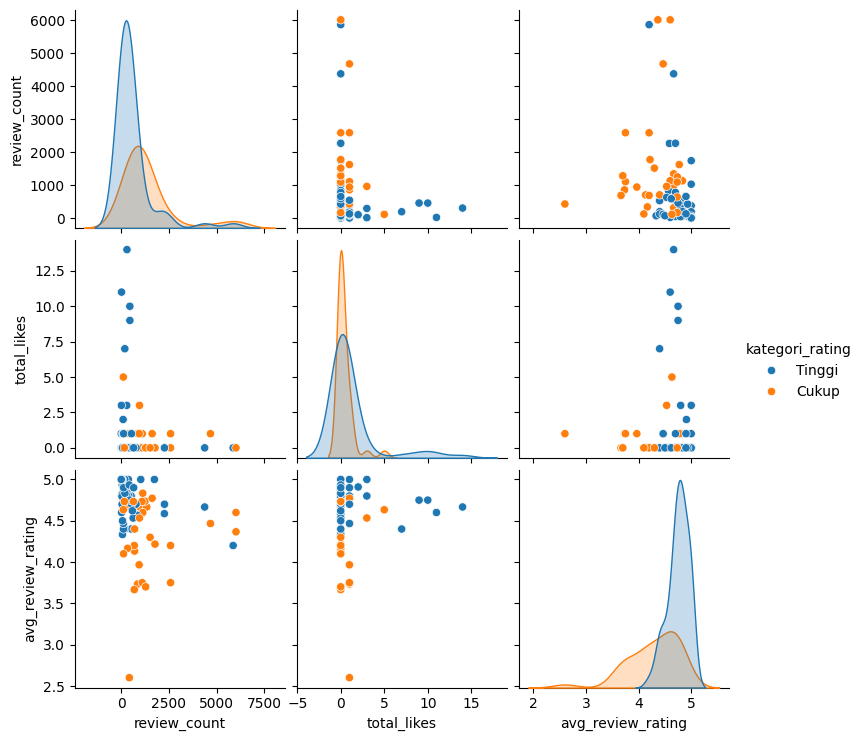

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Visualisasi pairplot berdasarkan kategori rating
sns.pairplot(data[['review_count', 'total_likes', 'avg_review_rating', 'kategori_rating']],
             hue='kategori_rating', diag_kind='kde')
plt.show()

#Langkah 4: Preprocessing

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Memilih fitur (X) dan label (y)
X = data[['review_count', 'total_likes', 'avg_review_rating']]
y = data['kategori_rating']

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi fitur
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

#Langkah 5: Buat Model kNN

In [9]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)
print("Model kNN berhasil dilatih!")

Model kNN berhasil dilatih!


#Langkah 6: Evaluasi Model kNN

In [11]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Prediksi pada data uji
y_pred = knn.predict(X_test)

# Menampilkan hasil evaluasi
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.8275862068965517
Confusion Matrix:
 [[10  0]
 [ 5 14]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

       Cukup       0.67      1.00      0.80        10
      Tinggi       1.00      0.74      0.85        19

    accuracy                           0.83        29
   macro avg       0.83      0.87      0.82        29
weighted avg       0.89      0.83      0.83        29



#Langkah Tambahan: Evaluasi Berbagai Nilai $K$ vs Akurasi

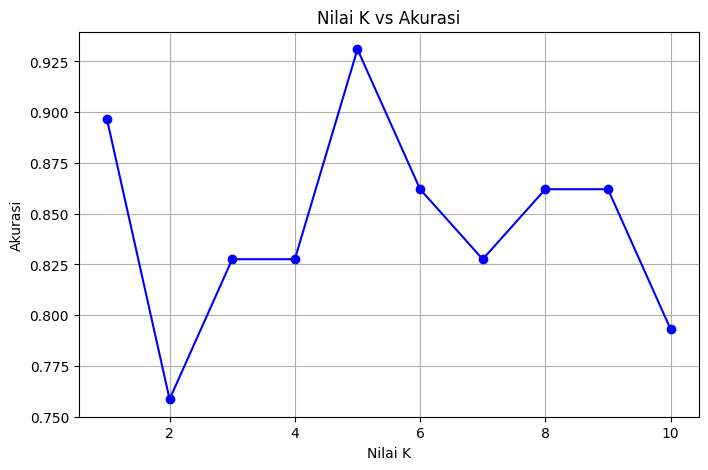

In [10]:
# Evaluasi berbagai nilai K
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

# Visualisasi Nilai K vs Akurasi
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), acc, marker='o', linestyle='-', color='b')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.grid(True)
plt.show()